# Calibration

Starfold looks for groups of similar rows in a table (rows are objects, columns are
measurements). It combines three tools:

- **UMAP** (McInnes, Healy and Melville 2018, arXiv:1802.03426) draws a
  low-dimensional map of the table, called an *embedding*. Rows with similar values
  land close together on the map.
- **HDBSCAN** (Campello, Moulavi and Sander 2013,
  doi:10.1007/978-3-642-37456-2_14) calls the dense regions of that map groups. It
  leaves the sparse rest unassigned, and those rows are called *noise*.
- **Optuna** (Akiba et al. 2019, arXiv:1907.10902) tries many settings of the first
  two tools and keeps the one that scores best.

This pipeline has a weakness. With enough settings tried, it finds groups in almost
any table, even a table that has none. Picture a smooth, round cloud of points: cut
it into pieces and the pieces look tidy, although no real group is there.

The calibration test guards against this. It builds copies of your table that keep
its columns but have no groups, runs the same search on each copy, and asks whether
your table scores higher than the copies. This notebook shows what such a copy looks
like and reads the tests recorded on two tables: the scikit-learn digits dataset
and the APOGEE DR19 example table. It runs no fits, so it finishes in seconds.

The manual covers the same ground at
[Copies and gaps](https://andreaswneitzel.github.io/Starfold/concepts/copies-and-gaps.html)
and
[Calibration p-value](https://andreaswneitzel.github.io/Starfold/metrics/calibration-p.html).

## Terms used here

Notebook 01 explains these terms more slowly, and the manual has a
[glossary](https://andreaswneitzel.github.io/Starfold/glossary.html).

- **Fit:** one UMAP embedding followed by one HDBSCAN clustering.
- **Setting:** one choice of the six values that steer UMAP and HDBSCAN:
  `n_neighbors`, `min_dist`, `n_components`, `min_cluster_size`, `min_samples` and
  `selection_method`.
- **Trial:** one setting that Optuna tries. Each trial fits UMAP and HDBSCAN on
  3 random subsets, each holding 80 percent of the rows.
- **Seed:** the number that starts a random number generator. The same seed gives
  the same random choices, so a run can be repeated exactly.
- **Score:** one number for a trial, built from three measures that never look at
  the number of groups. The first asks whether fits on different subsets agree on
  the groups. The second is *coverage*, the share of rows that get a group. The third
  is *modularity*, which asks whether the groups follow the links between each row
  and its nearest neighbours in the table. The score is zero if any of the three is
  zero.
- **Structureless copy:** a table with the same columns and the same values in each
  column, but no groups. The next sections show how one is made.
- **Gap:** the score of a trial on a table minus its score on a structureless copy
  of that table. The search maximises the gap, so every score in this notebook is a
  gap.
- **Flag:** a short named warning that Starfold attaches to a result, such as
  `null_not_run`. Not every flag is a fault. The manual lists them all under
  [Flags](https://andreaswneitzel.github.io/Starfold/reference/flags.html).

## The idea of a null test

A null test starts from a boring explanation, called the *null hypothesis*. Here
the boring explanation is: "this table has no groups, and the search only found
what it finds in any table." You then build many tables where the boring
explanation is true by construction. These are the structureless copies.

Think of a lottery. You bought one ticket (your table) and 19 other people bought
tickets drawn at random (the copies). If your ticket beats all 19, either you were
lucky or your ticket is different. The p-value measures how lucky you would have to
be.

In this test, the number each ticket carries is called the *statistic*. It is the
best gap among the first 17 trials of the search. These 17 trials are the library
defaults (trial 0) and 16 settings spread evenly over the search range. They come
from a *Sobol design*, a way of covering a range without clumps or holes. Each copy
goes through the same 17 trials with the same subsets and seeds, so the copies are
searched exactly as hard as your table.

## What the p-value answers

The p-value is the fraction of copies whose statistic is at least as high as the
table's, counting the table itself as one more draw. A small p-value means that few
copies, searched as hard as the table, score as high as the table does.

It does not tell you:

- the probability that the groups are real;
- how many groups there are, or whether any one group is real;
- how your table compares with any kind of copy other than the family you
  declared (the next sections explain families).

## What it costs

To score one trial on a copy, the search needs the gap of that copy. The gap is
measured against a structureless copy of the copy. So every trial fits 3 subsets of
the copy and 3 subsets of its own structureless copy. That is 6 fits per trial and
102 fits for the 17 trials of one copy.

The test draws up to 19 copies, which is 1,938 fits. That is about six times the
fits of the rest of a run. Because of this cost, `starfold.recover` (the main
function, which runs the search and the refits) skips the test by default. You run
it as a separate step with `starfold.null_test`.

This notebook does not rerun the 1,938 fits that each recorded test below made.

The next cell finds the root folder of the repository and makes its `bench`
package importable. It stops with a clear message if you run the notebook from
outside a clone.

In [1]:
import sys
from pathlib import Path

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    msg = "Run this notebook from inside a clone of the starfold repository."
    raise FileNotFoundError(msg)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

The next cell loads the libraries: NumPy for arrays, Matplotlib for plots, SciPy for
a rank correlation, and two parts of Starfold.

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
from bench.datasets import example_table
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr

import starfold
from starfold.nulls import monte_carlo_pvalue

The next cell holds the values you may want to change. `RANDOM_STATE` is the seed,
`ENGINE` picks the software that runs the fits, and `FIGURES` decides whether plots
are also written to disk.

In [3]:
RANDOM_STATE = 0
# "auto" uses cuML when it imports and sees a GPU, and warns when it falls back to the CPU.
ENGINE = "auto"
N_JOBS = 1
# Set to ROOT / "docs" / "figures" to rewrite the PNG figures that the manual shows.
FIGURES = None

The next cell points to the folder of recorded test results and defines a helper
that saves a figure only when `FIGURES` is set.

In [4]:
RECORDS = ROOT / "bench" / "results"


def save_figure(fig, name):
    """Write a figure under FIGURES at 150 dpi; do nothing when FIGURES is None."""
    if FIGURES is None:
        return
    folder = Path(FIGURES)
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / name, dpi=150, bbox_inches="tight")

## What a structureless copy is

A copy invents nothing. It keeps every value of every column and changes only which
row each value sits in. Picture a deck of cards, one deck per column: a copy
reshuffles the decks, so every card is still there, but cards that used to sit
together in one row may now sit in different rows.

There are two *families* (kinds of copy). Both rely on the word *marginal*. The
marginal of a column is its values on their own, with the other columns ignored. A
histogram of one column shows its marginal.

- `gaussian_copula` (the default) reorders each column so that the columns keep one
  smooth, elliptical trend between them. A *copula* is the part of a table's joint
  behaviour that is left once each column's marginal is set aside. A Gaussian copula
  keeps only the correlations between pairs of columns. In practice, it measures
  those correlations on the ranks of the values, draws random points that have them,
  and hands the observed values of each column back in the order of the drawn
  points.
- `independent_marginals` shuffles each column on its own, which removes the trend
  as well.

A copy keeps anything visible in one column alone, such as two peaks in a
histogram. It removes structure that shows only when columns are combined. A test
against `gaussian_copula` copies therefore asks for more than a trend: your table
has to score higher than tables that have that trend and nothing else.

In a plot of [Fe/H] against [Mg/Fe], the 9,242 real stars of the APOGEE DR19 example
table form two sequences, the high- and low-alpha discs of the Milky Way. The next
cell draws one copy of each family. It checks that every column of each copy holds exactly the
observed values, and stops with an error if not.

It also prints two things. The first is the *Spearman correlation* between the two
columns, for the data and for each copy. This is the ordinary correlation computed
on ranks: 0 means no trend, and +1 or -1 means a perfect rising or falling trend.
The second is the share of rows whose values changed.

In [5]:
x_apogee, names = example_table()
fe_h, mg_fe = names.index("fe_h"), names.index("mg_fe")
copies = {
    family: starfold.generate_null(x_apogee, family, seed=RANDOM_STATE)
    for family in ("gaussian_copula", "independent_marginals")
}

rho = spearmanr(x_apogee[:, fe_h], x_apogee[:, mg_fe]).statistic
print(f"{'data':22s} Spearman [Fe/H] vs [Mg/Fe] {rho:+.2f}")
for family, copy in copies.items():
    # Sorting each column must give back the observed values exactly.
    if not np.array_equal(np.sort(copy, axis=0), np.sort(x_apogee, axis=0)):
        msg = f"A column of the {family} copy does not hold the observed values."
        raise RuntimeError(msg)
    rho = spearmanr(copy[:, fe_h], copy[:, mg_fe]).statistic
    moved = np.mean(np.any(copy != x_apogee, axis=1))
    print(
        f"{family:22s} Spearman [Fe/H] vs [Mg/Fe] {rho:+.2f}, "
        f"sorted columns identical, {moved:.1%} of rows changed"
    )

data                   Spearman [Fe/H] vs [Mg/Fe] -0.67
gaussian_copula        Spearman [Fe/H] vs [Mg/Fe] -0.61, sorted columns identical, 100.0% of rows changed
independent_marginals  Spearman [Fe/H] vs [Mg/Fe] +0.00, sorted columns identical, 100.0% of rows changed


In the recorded run, the data has a Spearman correlation of -0.67. The
`gaussian_copula` copy keeps most of that falling trend (-0.61), and the
`independent_marginals` copy has none (+0.00). In both copies every row changed, yet
every column still holds the same values.

The figure below plots [Fe/H], the iron abundance of a star, against [Mg/Fe], its
magnesium abundance relative to iron. Both are on a base-10 logarithmic scale
relative to the Sun, in units called dex (0.1 dex is a factor of 1.26).

- **Top row:** the same plane in three tables. Each square bin is coloured by how
  many stars fall in it, on one shared logarithmic colour scale (empty bins stay
  white). The left panel is the data. The middle panel is the `gaussian_copula`
  copy: the same values, held together by a smooth trend, but without the two
  separate sequences. The right panel is the `independent_marginals` copy, with no
  trend at all.
- **Bottom row:** a histogram of each column alone, for the data (blue fill), the
  `gaussian_copula` copy (orange line) and the `independent_marginals` copy (green
  dashed line). The three coincide, because a copy only reorders each column.

If the two sequences are what makes your table special, the copies lack them, and
the test has a chance to detect them.

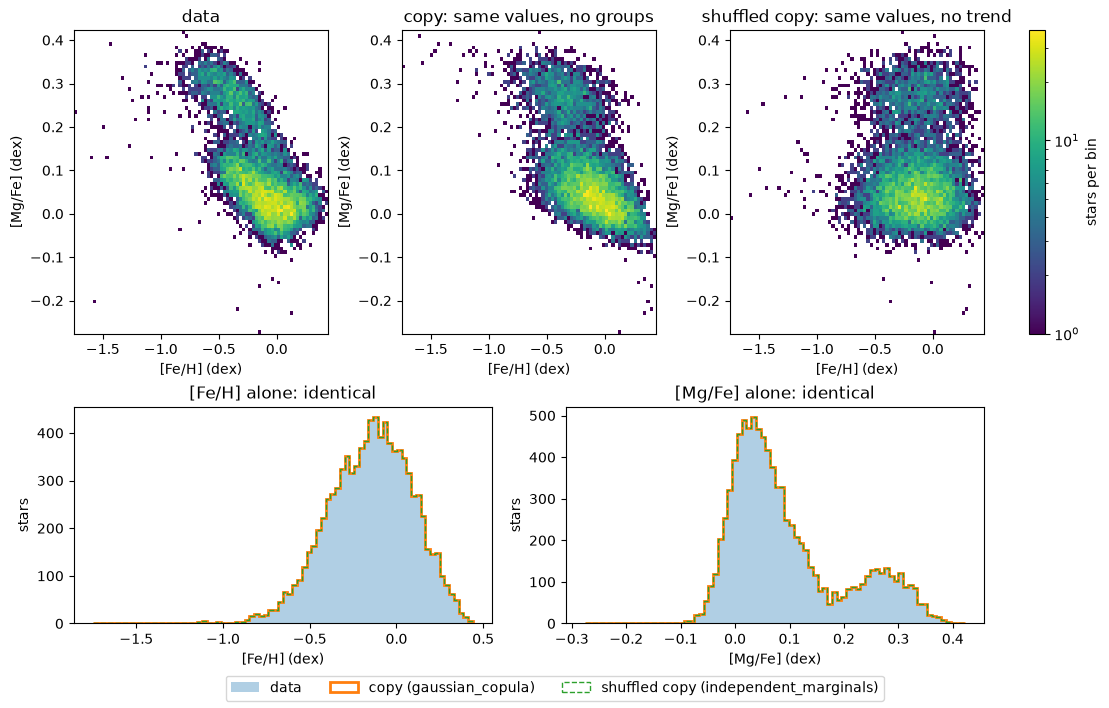

In [6]:
panels = {
    "data": x_apogee,
    "copy: same values, no groups": copies["gaussian_copula"],
    "shuffled copy: same values, no trend": copies["independent_marginals"],
}
fe_edges = np.linspace(x_apogee[:, fe_h].min(), x_apogee[:, fe_h].max(), 81)
mg_edges = np.linspace(x_apogee[:, mg_fe].min(), x_apogee[:, mg_fe].max(), 81)
counts = {
    title: np.histogram2d(matrix[:, fe_h], matrix[:, mg_fe], bins=(fe_edges, mg_edges))[0]
    for title, matrix in panels.items()
}
norm = LogNorm(vmin=1, vmax=max(c.max() for c in counts.values()))

fig, axes = plt.subplot_mosaic(
    [["j0", "j0", "j1", "j1", "j2", "j2"], ["m0", "m0", "m0", "m1", "m1", "m1"]],
    figsize=(11, 7),
    height_ratios=(1.4, 1),
    layout="constrained",
)
for i, (title, count) in enumerate(counts.items()):
    ax = axes[f"j{i}"]
    mesh = ax.pcolormesh(
        fe_edges, mg_edges, np.ma.masked_equal(count.T, 0), cmap="viridis", norm=norm
    )
    ax.set(title=title, xlabel="[Fe/H] (dex)", ylabel="[Mg/Fe] (dex)")
fig.colorbar(mesh, ax=[axes["j0"], axes["j1"], axes["j2"]], label="stars per bin")

for ax, column, edges, label in (
    (axes["m0"], fe_h, fe_edges, "[Fe/H]"),
    (axes["m1"], mg_fe, mg_edges, "[Mg/Fe]"),
):
    ax.hist(x_apogee[:, column], bins=edges, color="C0", alpha=0.35, label="data")
    ax.hist(
        copies["gaussian_copula"][:, column],
        bins=edges,
        histtype="step",
        color="C1",
        linewidth=2,
        label="copy (gaussian_copula)",
    )
    ax.hist(
        copies["independent_marginals"][:, column],
        bins=edges,
        histtype="step",
        color="C2",
        linestyle="--",
        label="shuffled copy (independent_marginals)",
    )
    ax.set(title=f"{label} alone: identical", xlabel=f"{label} (dex)", ylabel="stars")
handles, labels = axes["m0"].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
save_figure(fig, "apogee_surrogate.png")
plt.show()

## Running the test

`starfold.null_test` makes every copy go through exactly the steps your table went
through. To do that, it needs:

- the rows the search used;
- the record of the search itself;
- the same `Config`, seed and engine, and the same `n_jobs` (the number of parallel
  workers) when a resample holds more than 20,000 rows.

`Config` holds the declared budgets and rules of a run: the number of trials,
subsets and copies, the family of copy, the level `alpha` and the search range. The
search range is a `Space` object. If you searched a custom `Space`, pass that
`Config` again. The engine is the software that runs the fits: cuML on a GPU, or a
CPU fallback. A run saved on cuML must be tested on a machine where cuML works. Run
the test once, on the result you report.

The cell below shows the calls and is commented out, because it needs your own
table `X`. `result.kept_rows` are the row numbers of `X` that were finite and used.
Rows with a missing value are dropped, never filled. `result.search` is the record
of the search. The last line prints the p-value and `structure_supported`, both
explained below. The manual has a step-by-step page
([how-to](https://andreaswneitzel.github.io/Starfold/howto/run-calibration-test.html)).

In [7]:
# result = starfold.recover(X, random_state=0)
# null = starfold.null_test(X[result.kept_rows], result.search, random_state=0)
# print(null.p_value, null.structure_supported)

## Recorded results

The two records below come from `python -m bench.null_stage digits <saved run>`
and `python -m bench.null_stage apogee <saved run>` at the default budgets: up to 19
`gaussian_copula` copies and alpha = 0.05. Each record is a JSON file in
`bench/results/` with these fields:

- `observed`: the statistic of the table, its best gap over the 17 trials;
- `null_values`: the statistic of each copy, one value per copy, on the same scale;
- `exceedances`: how many copies have a statistic at or above `observed` (called h
  below). A tie counts against the data;
- `n_realisations`: how many copies were drawn (called L below);
- `p_value`: (h + 1) / (L + 1);
- `p_intervals`: a 95 percent *Monte Carlo interval* on h / L. A Monte Carlo method
  answers a question by random draws instead of a formula. Because only a few
  copies are drawn, h / L is itself uncertain, and this interval shows by how much;
- `structure_supported`: true when `p_value` is at most `alpha` (0.05), false
  otherwise;
- `n_fits`: the fits spent.

The next cell prints one line per record with these values.

In [8]:
records = {
    name: json.loads((RECORDS / f"{name}_null.json").read_text()) for name in ("digits", "apogee")
}
for name, record in records.items():
    low, high = record["p_intervals"][0]
    print(
        f"{name:7s} observed {record['observed']:.3f}, {record['n_realisations'][0]} copies, "
        f"{record['exceedances'][0]} at or above the data, p {record['p_value']:.2f}, "
        f"fraction at or above {low:.3f} to {high:.3f} (95% Monte Carlo interval), "
        f"{record['n_fits']} fits, supported {record['structure_supported']}"
    )

digits  observed 0.710, 19 copies, 0 at or above the data, p 0.05, fraction at or above 0.000 to 0.176 (95% Monte Carlo interval), 1938 fits, supported True
apogee  observed 0.362, 19 copies, 1 at or above the data, p 0.10, fraction at or above 0.001 to 0.260 (95% Monte Carlo interval), 1938 fits, supported False


Each line of the output gives, for one table, its statistic, the number
of copies, how many copies reached it, the p-value, the Monte Carlo interval, the
fits spent and whether structure is supported. The figures and the paragraph after
them interpret these numbers.

Each figure below shows the statistics of the 19 copies as blue
bars (the y axis counts copies) and the statistic of the data as a dashed black
line. The x axis is the best gap over the 17 opening trials. A line to the right of
every bar means that no copy reached the data. The title gives the p-value and the
95 percent interval on the share of copies at or above the data.

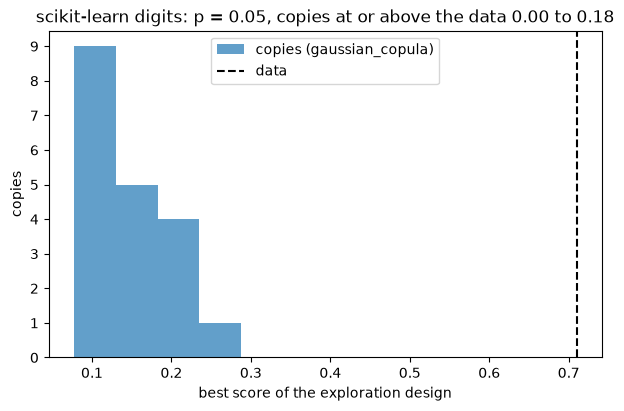

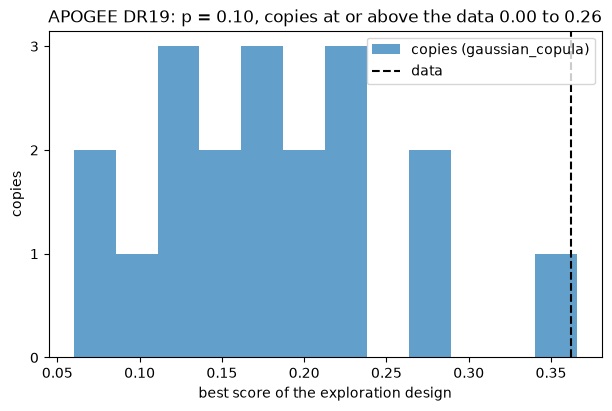

In [9]:
titles = {"digits": "scikit-learn digits", "apogee": "APOGEE DR19"}
for name, record in records.items():
    fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
    values = np.asarray(record["null_values"][0])
    edges = np.histogram_bin_edges(np.append(values, record["observed"]), bins=12)
    ax.hist(values, bins=edges, color="C0", alpha=0.7, label="copies (gaussian_copula)")
    ax.axvline(record["observed"], color="black", linestyle="--", label="data")
    low, high = record["p_intervals"][0]
    ax.set(
        title=(
            f"{titles[name]}: p = {record['p_value']:.2f}, copies at or above the data "
            f"{low:.2f} to {high:.2f}"
        ),
        xlabel="best score of the exploration design",
        ylabel="copies",
    )
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    save_figure(fig, f"{name}_null.png")
    plt.show()

On the digits table, no copy scored as high as the data. The best copy reached 0.24
and the data 0.71, so h = 0 and p sits at its floor of 0.05. Because p is at most alpha,
`structure_supported` is true: the table scores higher than all 19 copies of the
declared family. This says the table is unlike these copies. It does not say the
groups are correct, and a stable partition is not automatically a true one.

On the APOGEE table, one copy (0.366) scored slightly above the data (0.362), so h = 1 and
p = 2 / 20 = 0.10. That is above alpha, so at 19 copies the test does not support
structure for the table as a whole. This is not a finding of no groups. It means
that one copy which keeps the table's overall trend, searched as hard, scored as
high as the table. With 19 copies, you cannot tell how often that happens: the
interval on h / L runs from 0.001 to 0.260, which is wide.

## Why 0.05 is the smallest p-value at 19 copies

With h of L copies at or above the data, p = (h + 1) / (L + 1). The data count as
one more draw (Phipson and Smyth 2010, doi:10.2202/1544-6115.1585), so p can never
be exactly 0. Back to the lottery: even if your ticket beats all 19 others, you
cannot claim better odds than 1 in 20, because 20 tickets were in the draw.

With all 19 copies below the data, p = 1 / 20 = 0.05. This is exactly the default
alpha, the level at which the test declares the structure supported. So p = 0.05
means that no copy scored as high as the data. It does not say by how much the data
beat them.

The test stops early once 3 copies reach the data (Besag and Clifford 1991,
doi:10.1093/biomet/78.2.301). After that, p is at least 4 / 20 and cannot reach
0.05, so more copies would only refine a p-value already above alpha.

The interval is the 95 percent Clopper-Pearson range of the fraction h / L (Clopper
and Pearson 1934, doi:10.1093/biomet/26.4.404). In words, it is the range of true
fractions that could plausibly produce the observed h out of L. It is not an
interval on p. It says nothing about the table beyond the 19 copies drawn, and it
measures Monte Carlo precision only. For 1 exceedance in 19 it runs from 0.001 to
0.260.

The next cell applies the formula. Each row is a number of copies L, and the four
columns give p when h = 0, 1, 2 or 3 copies reach the data. The first column is the
floor for that L.

In [10]:
print("copies   p for h = 0, 1, 2, 3 copies at or above the data")
for n_copies in (4, 9, 19, 99):
    row = "  ".join(f"{monte_carlo_pvalue(h, n_copies):.3f}" for h in range(4))
    print(f"{n_copies:6d}   {row}")

copies   p for h = 0, 1, 2, 3 copies at or above the data
     4   0.200  0.400  0.600  0.800
     9   0.100  0.200  0.300  0.400
    19   0.050  0.100  0.150  0.200
    99   0.010  0.020  0.030  0.040


With 4 copies the floor is 0.200, so a test at alpha = 0.05
can never pass. With 99 copies the floor drops to 0.010. More copies buy a lower
floor, at the cost of more fits.

Two fields of `Config` control this. `n_null_max` is the most copies the test may
draw (19 by default), and `alpha` is the level at which it declares the structure
supported (0.05 by default). `dataclasses.replace(config, n_null_max=99)` returns a
copy of the `Config` with only that field changed. It brings the floor to 0.01, at
up to 10,098 fits. Neither field changes the search, so the copies still go through
the same steps as the data.

## Attaching the test to a saved result

A result from `recover` with the test off carries an empty null (the null is the
record of the calibration test). It also carries the flag `null_not_run` and a
placeholder p of 1.0.

To attach the test, replace the null with `dataclasses.replace` and re-derive the
flags with `starfold.result.derive_flags` in the same step. This matters because
`starfold.load` re-derives the flags from the evidence and refuses a result whose
stored flags differ.

The provenance is the record of the versions, seeds, budgets and engine of the
`recover` run. It still describes that run, while the null records its own
families, fits and seconds. `starfold.save` writes the result with checksums (short
fingerprints of each file), and `starfold.load` checks them. The manual covers this
under [Save and load](https://andreaswneitzel.github.io/Starfold/howto/save-and-load.html).

The cell below is commented out because it needs a saved result and takes the time
of the test.

In [11]:
# import dataclasses
# from starfold.result import derive_flags
# provenance = result.provenance
# calibrated = dataclasses.replace(
#     result,
#     null=null,
#     flags=derive_flags(
#         labels=result.labels,
#         search=result.search,
#         worlds=result.worlds,
#         consensus=result.consensus,
#         null=null,
#         backends=result.backends,
#         rows_rejected=int(provenance["n_input_rows"]) - int(provenance["n_kept_rows"]),
#         n_jobs_forced=bool(provenance["n_jobs_forced_to_one_on_cuml"]),
#     ),
# )
# starfold.save(calibrated, ROOT / "runs" / "digits_null")